In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
df = pd.read_csv('student_scores_clean.csv')

In [3]:
print('۵ سطر اول:')
print(df.head())

print('\n۵ سطر آخر:')
print(df.tail())

print('\nاطلاعات کلی:')
df.info()

print('\nابعاد دیتاست:', df.shape)

print('\nآمار توصیفی:')
print(df.describe())

print('\nمقادیر خالی در هر ستون:')
print(df.isnull().sum())

print('\nتعداد سطرهای تکراری:', df.duplicated().sum())


۵ سطر اول:
   StudyHours  Attendance  PreviousGrade  FinalScore
0        0.92        87.2            8.4        9.59
1        4.72        94.0           16.5       16.22
2        4.12        92.7           16.6       14.80
3        1.65        72.5           18.9       10.06
4        4.03        89.4           19.3       14.82

۵ سطر آخر:
     StudyHours  Attendance  PreviousGrade  FinalScore
455        4.93        87.8           12.1       16.20
456        4.35        80.5           11.6       14.01
457        2.03        68.9           10.2        8.50
458        1.95        81.5           16.2       10.67
459        2.74        77.8           12.5       10.89

اطلاعات کلی:
<class 'pandas.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   StudyHours     460 non-null    float64
 1   Attendance     460 non-null    float64
 2   PreviousGrade  460 non-null    float64
 3

In [4]:
max_study = df['StudyHours'].max()
min_study = df['StudyHours'].min()
mean_study = df['StudyHours'].mean()

print('\nبیشترین ساعات مطالعه:', max_study)
print('کمترین ساعات مطالعه:', min_study)
print('میانگین ساعات مطالعه:', mean_study)



بیشترین ساعات مطالعه: 4.99
کمترین ساعات مطالعه: 0.0
میانگین ساعات مطالعه: 2.6110652173913045


In [5]:
max_final = df['FinalScore'].max()
min_final = df['FinalScore'].min()
mean_final = df['FinalScore'].mean()

print('\nبیشترین نمره نهایی:', max_final)
print('کمترین نمره نهایی:', min_final)
print('میانگین نمره نهایی:', mean_final)



بیشترین نمره نهایی: 18.21
کمترین نمره نهایی: 5.08
میانگین نمره نهایی: 11.667282608695652



ماتریس همبستگی:
               StudyHours  Attendance  PreviousGrade  FinalScore
StudyHours       1.000000   -0.003656      -0.017964    0.473889
Attendance      -0.003656    1.000000       0.010577    0.406910
PreviousGrade   -0.017964    0.010577       1.000000    0.364791
FinalScore       0.473889    0.406910       0.364791    1.000000


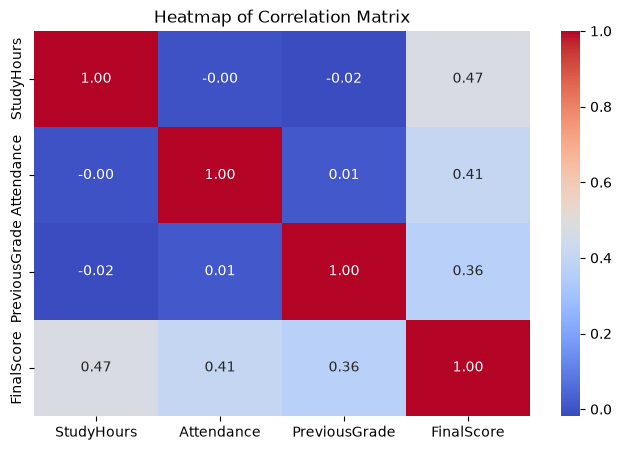


ویژگی با بیشترین تأثیر روی FinalScore: StudyHours
ویژگی با کمترین تأثیر روی FinalScore: PreviousGrade


In [6]:
correlation_matrix = df.corr(numeric_only=True)

print('\nماتریس همبستگی:')
print(correlation_matrix)

plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap of Correlation Matrix')
plt.show()

# یافتن بیشترین و کمترین تأثیر روی FinalScore
final_corr = correlation_matrix['FinalScore'].drop('FinalScore')
most_effective = final_corr.abs().idxmax()
least_effective = final_corr.abs().idxmin()

print('\nویژگی با بیشترین تأثیر روی FinalScore:', most_effective)
print('ویژگی با کمترین تأثیر روی FinalScore:', least_effective)


In [7]:
x = df[['StudyHours', 'Attendance', 'PreviousGrade']]
y = df['FinalScore']

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [9]:
model = LinearRegression()
model.fit(x_train, y_train)


print('\nضرایب مدل:', model.coef_)
print('عبارت ثابت (Intercept):', model.intercept_)


ضرایب مدل: [0.71143066 0.07485225 0.22539396]
عبارت ثابت (Intercept): 0.6081733300513719


In [10]:
y_pred = model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('\nمیزان خطای موسطبع:', mse)
print('میزان خطای مطلق میانگین:', mae)
print('امتیاز R²:', r2)


میزان خطای موسطبع: 2.045125785174835
میزان خطای مطلق میانگین: 1.136457255618964
امتیاز R²: 0.5578208206753335


In [11]:
print('\n────────────────────────────')
study = float(input('ساعات مطالعه را وارد کنید: '))
attendance = float(input('درصد حضور در کلاس را وارد کنید: '))
previous = float(input('نمره قبلی را وارد کنید: '))

user_input = pd.DataFrame([[study, attendance, previous]], 
                          columns=['StudyHours', 'Attendance', 'PreviousGrade'])
predicted_score = model.predict(user_input)

print('\nنمره نهایی پیش‌بینی‌شده:', round(predicted_score[0], 2))


────────────────────────────

نمره نهایی پیش‌بینی‌شده: 9.12
